# Training time comparison

Reads the result spreadsheets written by the noise-sweep notebooks and draws grouped bars of training time per method, one group per model, on a log axis. Inside each bar is the mean time in seconds; above it the speed-up with respect to full backpropagation retraining.

Nothing below is hardcoded to a particular run:

* Each model folder is scanned for `results_*` sub-folders and the **newest** `.xlsx` in each one is loaded (sheet `long`).
* The mean and standard deviation are computed over every row a method has in its file (all noise levels and seeds).
* Trailing run details such as `(T=1.0,10ep)` are stripped from the method labels; baseline rows that occur in several files are taken from the BOLSTER file.

Run it from the `plots/` folder (or anywhere inside the project).

In [108]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator

In [109]:
FONT_FAMILY         = "DejaVu Sans"   # e.g. "serif", "Times New Roman", "Arial", ...
BASE_FONTSIZE       = 25              # default text size (titles, legend title, ...)
AXIS_LABEL_FONTSIZE = 17              # x/y axis label size
AXIS_TICK_FONTSIZE  = 17              # x/y tick label size
plt.rcParams.update({
    "font.family":     FONT_FAMILY,
    "font.size":       BASE_FONTSIZE,
    "axes.labelsize":  AXIS_LABEL_FONTSIZE,
    "axes.titlesize":  BASE_FONTSIZE + 1,
    "xtick.labelsize": AXIS_TICK_FONTSIZE,
    "ytick.labelsize": AXIS_TICK_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE - 3,
})

## Configuration

Only presentation choices live here (which folders become groups, how labels are displayed, colours, axis limits). All numbers come from the spreadsheets.

In [110]:
# Model folder -> x-axis label. The order here is the group order.
# Leave empty ({}) to auto-discover every folder under the project root that contains results_* sub-folders.
MODELS = {
    "lenet5_mnist":             "LeNet5/MNIST",
    "resnet20_cifar10":         "ResNet20/CIFAR10",
    "mobilenetv1_tinyimagenet": "MobileNet-v1/Tiny ImageNet",
}

RESULTS_DIR_GLOB = "results_*"        # sub-folders of each model folder that hold the xlsx files
SHEET_NAME       = "long"             # sheet with one row per (noise_level, method[, seed])
METRIC           = "train_time_sec"   # column to plot

# Label in the xlsx `method` column -> legend label. Trailing parentheses such as "(T=1.0,10ep)"
# are stripped before the lookup, so "LMC-SPSA(T=1.0,200ep)" matches the "LMC-SPSA" entry.
# Labels that are not listed are shown as they appear in the file.
DISPLAY_NAMES = {
    "Full retrain":      "Backpropagation",
    "Init (no retrain)": "No retrain",
    "BOLSTER":           "Ours",
    "LMC-SPSA":          "LMC",
    "Sparse-MeZO":       "SMEZO",
}
EXCLUDE_METHODS = {"BP-FC", "Init (no retrain)"}   # xlsx labels (after stripping) not to plot (no retrain has no training time)

# Rows that occur in several results_* folders (the baselines) are taken from this one when present.
PREFERRED_SOURCE = "bolster"

# Speed-ups are computed relative to this method (display name).
REFERENCE_METHOD = "Backpropagation"

# Bar order inside each group (display names). Methods not listed are appended alphabetically.
PLOT_ORDER = ["Backpropagation", "PEPITA", "SCFF", "SMEZO", "LMC", "Ours"]

# Colour per method (display names). Methods not listed take the next colour of the matplotlib cycle.
COLORS = {
    "Ours":            "tab:green",
    "Backpropagation": "tab:blue",
    "No retrain":      "black",
    "SCFF":            "orangered",
    "PEPITA":          "tab:orange",
    "SMEZO":           "tab:purple",
    "LMC":             "tab:gray",
}

BAR_WIDTH        = 0.1
# Standard-deviation whiskers: thin and grey so they do not hide the labels on short bars
# ERROR_BAR_STYLE  = dict(ecolor="0.3", elinewidth=1.0, capsize=3, capthick=1.0, zorder=5)
ERROR_BAR_STYLE  = dict(capsize=5, capthick=2.0, zorder=5)
PLAIN_TICK_MAX_EXP = 0      # decade ticks up to 10^0 are written as decimals (0.1, 1.0); larger ones as powers of ten (10^1, 10^2, ...)
YLIM             = None     # (bottom, top) of the log axis, or None to derive it from the data
SPEEDUP_DECIMALS = 3        # decimals of the speed-up label on top of each bar
FIGSIZE          = (12, 7)

OUTPUT_FILE = Path("figures") / "training_time_combined.png"

## Locate and load the result spreadsheets

In [111]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from `start` until a folder is found whose children contain results_* folders."""
    for candidate in (start, *start.parents):
        if any(p.is_dir() for p in candidate.glob(f"*/{RESULTS_DIR_GLOB}")):
            return candidate
    raise FileNotFoundError(f"No '*/{RESULTS_DIR_GLOB}' folders found in {start} or its parents")


def discover_models(root: Path) -> dict:
    """Return {model_folder: label}. Uses MODELS if given, otherwise every folder with results_* inside."""
    if MODELS:
        return dict(MODELS)
    found = sorted({p.parent.name for p in root.glob(f"*/{RESULTS_DIR_GLOB}") if p.is_dir()})
    return {name: name for name in found}


_TIMESTAMP_RE = re.compile(r"(\d{8}_\d{6})")

def latest_xlsx(results_dir: Path):
    """Newest .xlsx in a results_* folder: by the YYYYMMDD_HHMMSS stamp in the name, else by mtime."""
    files = [f for f in results_dir.glob("*.xlsx") if not f.name.startswith("~$")]
    if not files:
        return None
    def sort_key(f):
        m = _TIMESTAMP_RE.search(f.stem)
        return (m.group(1) if m else "", f.stat().st_mtime)
    return max(files, key=sort_key)


def source_from_dir(results_dir: Path, model_dir: str) -> str:
    """'results_lmc_spsa_resnet20_cifar10' with model 'resnet20_cifar10' -> 'lmc_spsa'."""
    name = results_dir.name
    if name.startswith("results_"):
        name = name[len("results_"):]
    suffix = f"_{model_dir}"
    if name.endswith(suffix):
        name = name[: -len(suffix)]
    return name


def load_results(root: Path, models: dict) -> pd.DataFrame:
    frames = []
    for model_dir in models:
        mdir = root / model_dir
        if not mdir.is_dir():
            print(f"[warn] model folder not found: {mdir}")
            continue
        for rdir in sorted(p for p in mdir.glob(RESULTS_DIR_GLOB) if p.is_dir()):
            f = latest_xlsx(rdir)
            if f is None:
                print(f"[warn] no .xlsx in {rdir.relative_to(root)}")
                continue
            df = pd.read_excel(f, sheet_name=SHEET_NAME)
            missing = {"method", METRIC} - set(df.columns)
            if missing:
                print(f"[warn] {f.relative_to(root)} lacks columns {sorted(missing)}; skipped")
                continue
            source = source_from_dir(rdir, model_dir)
            df["model"]  = model_dir
            df["source"] = source
            df["file"]   = str(f.relative_to(root))
            frames.append(df)
            print(f"{model_dir:26s} {source:12s} <- {f.relative_to(root)}  ({len(df)} rows)")
    if not frames:
        raise FileNotFoundError("No result spreadsheets were loaded")
    return pd.concat(frames, ignore_index=True)


PROJECT_ROOT = find_project_root()
models = discover_models(PROJECT_ROOT)
print(f"project root: {PROJECT_ROOT}\n")
raw = load_results(PROJECT_ROOT, models)

project root: /home/rahman2/GIT/BOLSTER

lenet5_mnist               bolster      <- lenet5_mnist/results_bolster_lenet5_mnist/results_bolster_lenet5_mnist_20261007_143254.xlsx  (40 rows)
lenet5_mnist               lmc_spsa     <- lenet5_mnist/results_lmc_spsa_lenet5_mnist/results_lmc_spsa_lenet5_mnist_20261007_150417.xlsx  (40 rows)
lenet5_mnist               pepita       <- lenet5_mnist/results_pepita_lenet5_mnist/results_pepita_lenet5_mnist_20261007_134721.xlsx  (20 rows)
lenet5_mnist               scff         <- lenet5_mnist/results_scff_lenet5_mnist/results_scff_lenet5_mnist_20260930_020107.xlsx  (20 rows)
lenet5_mnist               smezo_spsa   <- lenet5_mnist/results_smezo_spsa_lenet5_mnist/results_smezo_spsa_lenet5_mnist_20261007_145236.xlsx  (40 rows)
resnet20_cifar10           bolster      <- resnet20_cifar10/results_bolster_resnet20_cifar10/results_bolster_resnet20_cifar10_20261007_135331.xlsx  (40 rows)
resnet20_cifar10           lmc_spsa     <- resnet20_cifar10/results_lmc

## Normalise labels, pick one source per method and aggregate

In [112]:
_SUFFIX_RE = re.compile(r"\s*\([^()]*\)\s*$")   # trailing "(...)" e.g. "(T=1.0,10ep)"

def base_method(label) -> str:
    """Strip the trailing run details unless the full label is itself a known name."""
    label = str(label).strip()
    if label in DISPLAY_NAMES or label in EXCLUDE_METHODS:
        return label
    stripped = _SUFFIX_RE.sub("", label)
    return stripped or label


df = raw.copy()
df["method_base"] = df["method"].map(base_method)
df["method_name"] = df["method_base"].map(lambda b: DISPLAY_NAMES.get(b, b))
df = df[~df["method_base"].isin(EXCLUDE_METHODS)]
df = df[df[METRIC].notna()]

# A method that appears in several results_* folders (the baselines) is taken from PREFERRED_SOURCE
# when that folder reports it, otherwise from the first folder (alphabetically) that does.
priority = (df["source"] != PREFERRED_SOURCE).astype(int)
chosen = (df.assign(_prio=priority)
            .sort_values(["_prio", "source"])
            .groupby(["model", "method_name"])["source"].first()
            .rename("chosen_source"))
df = df.join(chosen, on=["model", "method_name"])
df = df[df["source"] == df["chosen_source"]].drop(columns="chosen_source")

# Mean / sample std / count over all rows of a method (every noise level and seed)
stats = (df.groupby(["model", "method_name"])[METRIC]
           .agg(mean="mean", std=lambda s: s.std(ddof=1), n="count")
           .reset_index())
stats["std"] = stats["std"].fillna(0.0)

# Speed-up relative to REFERENCE_METHOD within the same model
ref = stats[stats["method_name"] == REFERENCE_METHOD].set_index("model")["mean"]
stats["speedup"] = stats["model"].map(ref) / stats["mean"]

print("Sources:")
print(chosen.unstack("method_name").fillna("-").to_string(), "\n")

def ordered_methods(names) -> list:
    names = set(names)
    return [m for m in PLOT_ORDER if m in names] + sorted(names - set(PLOT_ORDER))

for model_dir, label in models.items():
    t = stats[stats["model"] == model_dir].set_index("method_name")
    if t.empty:
        continue
    t = t.loc[ordered_methods(t.index)]
    print(f"== {label} ({METRIC}: mean +/- std over n rows; speed-up vs {REFERENCE_METHOD})")
    print(t[["mean", "std", "n", "speedup"]].round(3).to_string(), "\n")

Sources:
method_name              Backpropagation       LMC     Ours  PEPITA  SCFF       SMEZO
model                                                                                
lenet5_mnist                     bolster  lmc_spsa  bolster  pepita  scff  smezo_spsa
mobilenetv1_tinyimagenet         bolster  lmc_spsa  bolster  pepita  scff  smezo_spsa
resnet20_cifar10                 bolster  lmc_spsa  bolster  pepita  scff  smezo_spsa 

== LeNet5/MNIST (train_time_sec: mean +/- std over n rows; speed-up vs Backpropagation)
                   mean    std   n  speedup
method_name                                
Backpropagation   2.210  0.047  10    1.000
PEPITA           17.364  0.045  10    0.127
SCFF             47.192  3.220  10    0.047
SMEZO             1.590  0.435  10    1.390
LMC               1.422  0.122  10    1.554
Ours              1.358  0.046  10    1.627 

== ResNet20/CIFAR10 (train_time_sec: mean +/- std over n rows; speed-up vs Backpropagation)
                      mea

## Plot

saved /home/rahman2/GIT/BOLSTER/plots/figures/training_time_combined.png


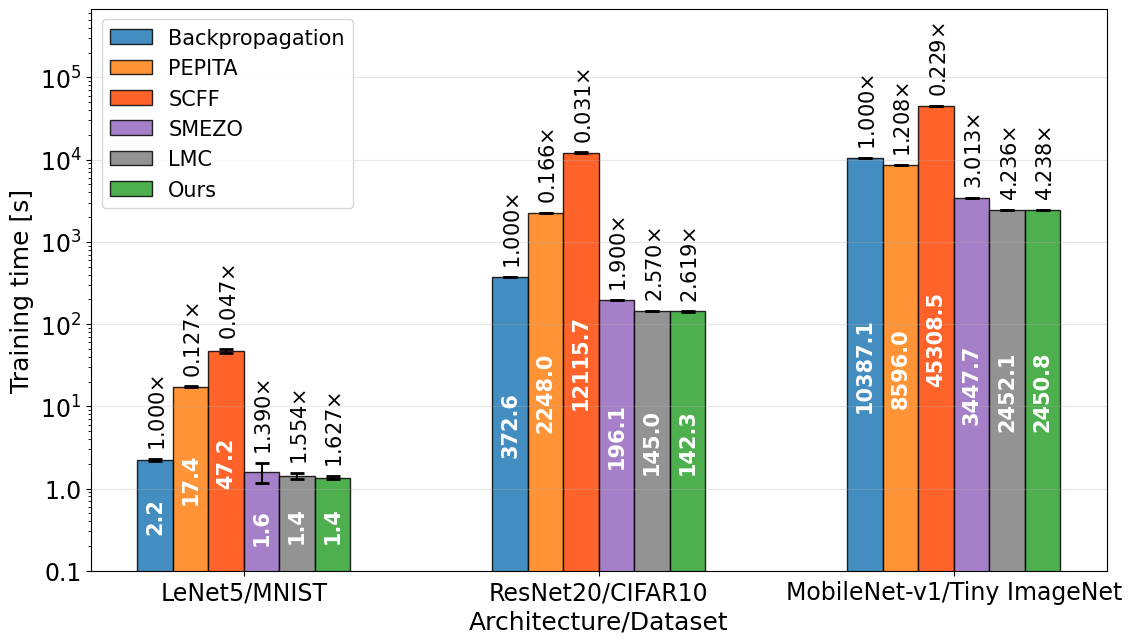

In [114]:
methods = ordered_methods(stats["method_name"].unique())
cycle = iter(plt.rcParams["axes.prop_cycle"].by_key()["color"] * 10)
colors = {m: COLORS.get(m) or next(cycle) for m in methods}

x = np.arange(len(models))
model_dirs = list(models)

if YLIM is None:
    # lower whisker ends (fall back to half the mean when the std exceeds the mean)
    lower_ends = np.where(stats["mean"] - stats["std"] > 0, stats["mean"] - stats["std"], stats["mean"] / 2)
    y_bottom = 10 ** (np.floor(np.log10(lower_ends.min())) - 1)   # >= one decade below the lowest whisker: room for the labels
    y_top    = (stats["mean"] + stats["std"]).max() * 15           # headroom for the speed-up labels
else:
    y_bottom, y_top = YLIM

plt.figure(figsize=FIGSIZE)

for i, m in enumerate(methods):
    offset = (i - (len(methods) - 1) / 2) * BAR_WIDTH
    rows = stats[stats["method_name"] == m].set_index("model").reindex(model_dirs)
    means, sds = rows["mean"].to_numpy(), rows["std"].to_numpy()
    present = ~np.isnan(means)

    plt.bar(x[present] + offset, means[present], BAR_WIDTH, yerr=sds[present],
            color=colors[m], edgecolor="black", label=m, error_kw=ERROR_BAR_STYLE,alpha=0.84)

    for xi, mean, sd, speedup in zip(x[present], means[present], sds[present], rows["speedup"].to_numpy()[present]):
        # mean value inside the bar, centred (geometrically, the axis is logarithmic) between the
        # bar bottom and the lower end of the whisker so the text never collides with the whisker
        lower = max(mean - sd, y_bottom * 1.05)
        y_mid = 10 ** ((np.log10(y_bottom) + np.log10(lower)) / 2)
        plt.text(xi + offset, y_mid, f"{mean:.1f}", ha="center", va="center",
                 fontsize=15, fontweight="bold", color="white", rotation=90)
        # speed-up vs the reference method, above the upper end of the whisker
        if np.isfinite(speedup):
            plt.text(xi + offset + 0.01, (mean + sd) * 1.3, f"{speedup:.{SPEEDUP_DECIMALS}f}$\\times$",
                     ha="center", va="bottom", fontsize=15, color="black", rotation=90)

plt.yscale("log")
plt.ylim(y_bottom, y_top)

# decade tick labels: decimals (0.1, 1.0) up to 10^PLAIN_TICK_MAX_EXP, powers of ten above

def _decade_label(v, _pos):

    k = int(round(np.log10(v)))

    return f"{10.0 ** k:.1f}" if -1 <= k <= PLAIN_TICK_MAX_EXP else f"$10^{{{k}}}$"

plt.gca().yaxis.set_major_locator(LogLocator(base=10))

plt.gca().yaxis.set_major_formatter(FuncFormatter(_decade_label))
plt.xticks(x, [models[d] for d in model_dirs])
plt.xlabel("Architecture/Dataset", fontsize=18)
plt.ylabel("Training time [s]", fontsize=18)
plt.grid(True, axis="y", alpha=0.3, which="major")
plt.legend(fontsize=15)

plt.tight_layout()
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
print(f"saved {OUTPUT_FILE.resolve()}")
plt.show()